# Análisis Exploratorio de Datos: Palmer Penguins

El **Análisis Exploratorio de Datos (EDA)** es el primer paso en cualquier proyecto de minería de datos. Su objetivo es entender la estructura, distribución y relaciones en los datos **antes** de aplicar cualquier modelo.

En este notebook utilizaremos el dataset **Palmer Penguins**, una alternativa moderna al clásico Iris, que contiene mediciones de tres especies de pingüinos recolectadas en el Archipiélago Palmer, Antártida.

## Contenido

1. **Carga y primer vistazo**: Importar datos y entender su estructura
2. **Calidad de datos**: Identificar y tratar valores faltantes
3. **Análisis univariado**: Distribución de cada variable
4. **Análisis bivariado**: Relaciones entre pares de variables
5. **Análisis multivariado**: Patrones en múltiples dimensiones
6. **Conclusiones**: Síntesis de hallazgos

---

### El dataset

| Variable | Tipo | Descripción |
|---|---|---|
| `species` | Categórica | Especie: Adelie, Chinstrap, Gentoo |
| `island` | Categórica | Isla: Biscoe, Dream, Torgersen |
| `bill_length_mm` | Numérica | Longitud del pico (mm) |
| `bill_depth_mm` | Numérica | Profundidad del pico (mm) |
| `flipper_length_mm` | Numérica | Longitud de la aleta (mm) |
| `body_mass_g` | Numérica | Masa corporal (g) |
| `sex` | Categórica | Sexo: male, female |

![Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/reference/figures/lter_penguins.png)
*Ilustración: Allison Horst*

## 0. Configuración del entorno

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Estilo global
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (10, 5)

# Colores por especie (consistentes en todo el notebook)
COLORES_ESPECIE = {
    "Adelie": "#E69F00",
    "Chinstrap": "#009E73",
    "Gentoo": "#56B4E9",
}

np.random.seed(42)

## 1. Carga y primer vistazo

In [2]:
# seaborn incluye el dataset directamente
df = sns.load_dataset("penguins")

print(f"Dimensiones: {df.shape[0]} filas × {df.shape[1]} columnas")
df.head()

Dimensiones: 344 filas × 7 columnas


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,Male,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observaciones iniciales:**
- El dataset tiene 344 registros y 7 columnas.
- Las variables numéricas son: longitud y profundidad del pico, longitud de aleta y masa corporal.
- Las variables categóricas son: especie, isla y sexo.
- Se observan algunos valores faltantes (`NaN`) que necesitamos cuantificar.

## 2. Calidad de datos

Antes de explorar, revisamos si los datos están completos y tienen sentido.

In [5]:
# Conteo y porcentaje de valores faltantes
faltantes = df.isnull().sum()
pct = (faltantes / len(df) * 100).round(2)

resumen_faltantes = pd.DataFrame({"Faltantes": faltantes, "Porcentaje (%)": pct}).query(
    "Faltantes > 0"
)

print("Variables con valores faltantes:")
print(resumen_faltantes.to_string())

Variables con valores faltantes:
                   Faltantes  Porcentaje (%)
bill_length_mm             2            0.58
bill_depth_mm              2            0.58
flipper_length_mm          2            0.58
body_mass_g                2            0.58
sex                       11            3.20


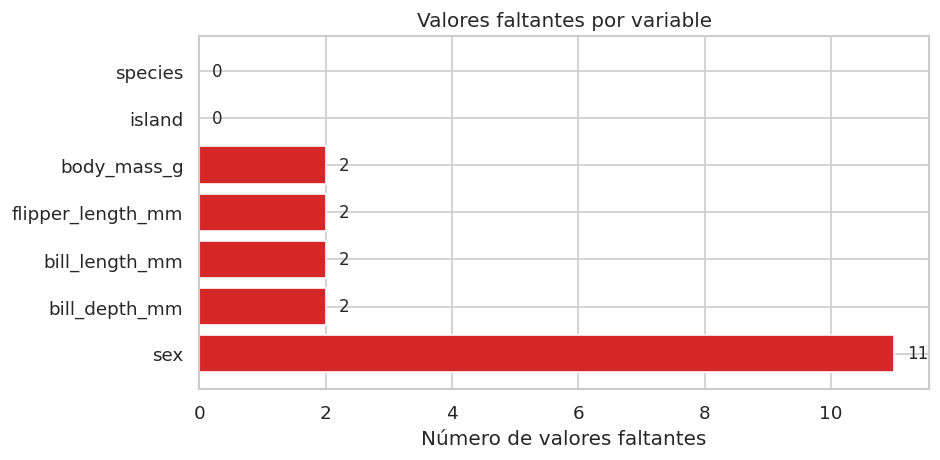

In [6]:
# Visualizar el patrón de valores faltantes
fig, ax = plt.subplots(figsize=(8, 4))

faltantes_plot = df.isnull().sum().sort_values(ascending=False)
colores = ["#d62728" if v > 0 else "#aec7e8" for v in faltantes_plot.values]

bars = ax.barh(faltantes_plot.index, faltantes_plot.values, color=colores)
ax.set_xlabel("Número de valores faltantes")
ax.set_title("Valores faltantes por variable")

for bar, val in zip(bars, faltantes_plot.values):
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va="center",
        fontsize=10,
    )

plt.tight_layout()
plt.show()

In [7]:
# Identificar las filas con valores faltantes
df[df.isnull().any(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


Los valores faltantes representan menos del 4% del total. Para el análisis exploratorio los eliminaremos para evitar distorsiones.

In [8]:
df_clean = df.dropna().reset_index(drop=True)
print(f"Registros originales : {len(df)}")
print(f"Registros tras limpiar: {len(df_clean)}")
print(f"Eliminados           : {len(df) - len(df_clean)}")

Registros originales : 344
Registros tras limpiar: 333
Eliminados           : 11


## 3. Análisis univariado

Estudiamos cada variable de forma individual para entender su distribución.

### 3.1 Variables categóricas

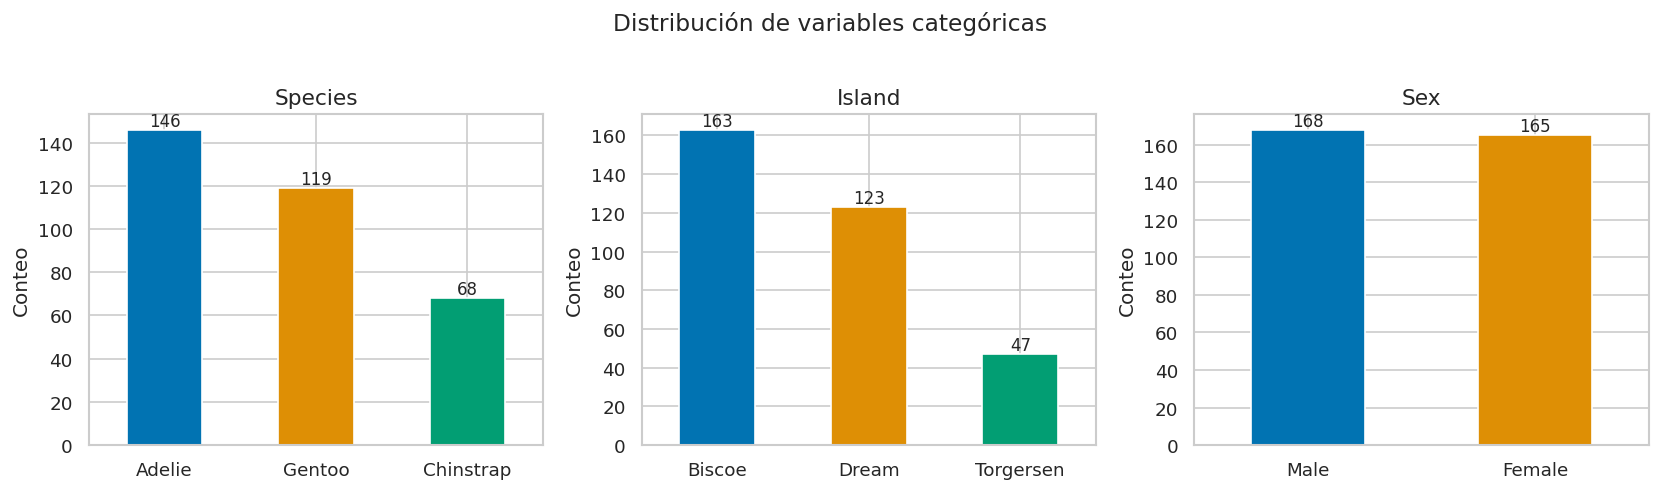

In [9]:
categoricas = ["species", "island", "sex"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, categoricas):
    conteo = df_clean[col].value_counts()
    conteo.plot(
        kind="bar",
        ax=ax,
        color=sns.color_palette("colorblind", len(conteo)),
        edgecolor="white",
        rot=0,
    )
    ax.set_title(col.capitalize(), fontsize=13)
    ax.set_ylabel("Conteo")
    ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(
            f"{int(p.get_height())}",
            (p.get_x() + p.get_width() / 2, p.get_height()),
            ha="center",
            va="bottom",
            fontsize=10,
        )

fig.suptitle("Distribución de variables categóricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Hallazgos:**
- La especie **Adelie** es la más frecuente (≈44%), seguida por Gentoo (≈36%) y Chinstrap (≈20%).
- La isla **Dream** concentra la mayor cantidad de observaciones, seguida de Biscoe y Torgersen.
- La distribución por **sexo** es prácticamente balanceada.

### 3.2 Variables numéricas

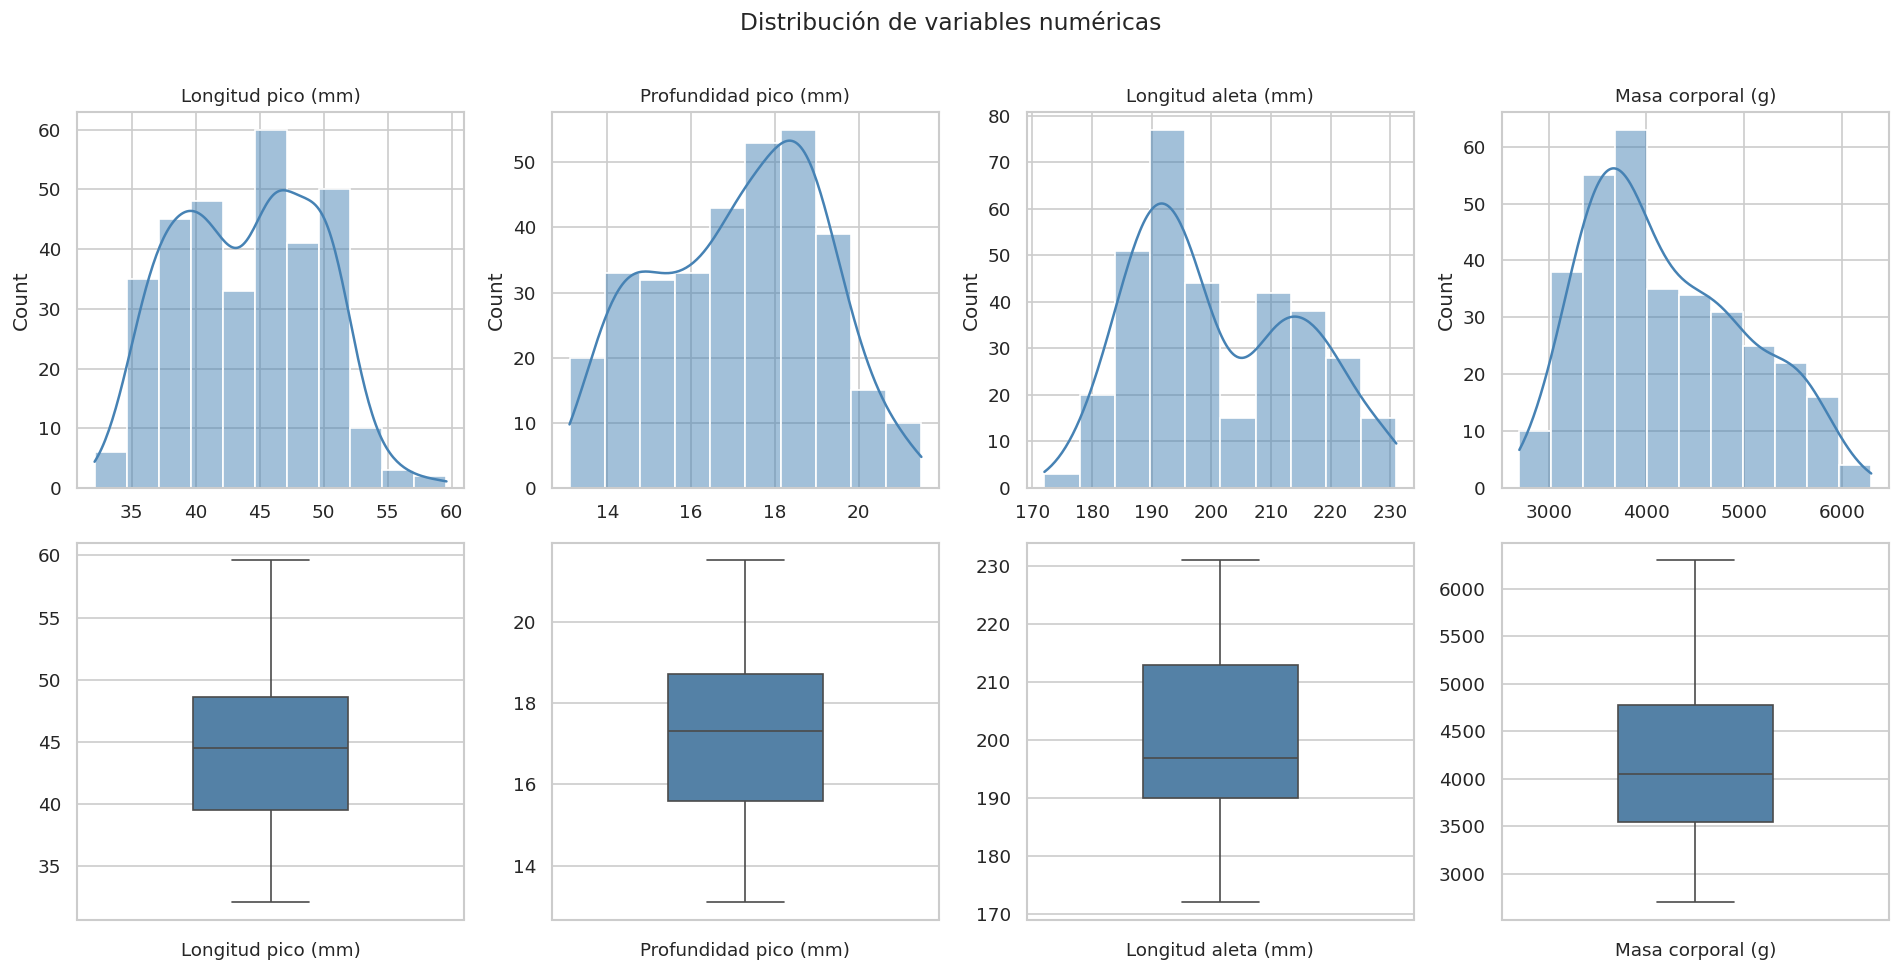

In [10]:
numericas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
etiquetas = [
    "Longitud pico (mm)",
    "Profundidad pico (mm)",
    "Longitud aleta (mm)",
    "Masa corporal (g)",
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, (col, etiqueta) in enumerate(zip(numericas, etiquetas)):
    # Histograma + KDE
    ax_hist = axes[0, i]
    sns.histplot(
        df_clean[col], kde=True, ax=ax_hist, color="steelblue", edgecolor="white"
    )
    ax_hist.set_title(etiqueta, fontsize=11)
    ax_hist.set_xlabel("")

    # Boxplot
    ax_box = axes[1, i]
    sns.boxplot(
        y=df_clean[col],
        ax=ax_box,
        color="steelblue",
        width=0.4,
        flierprops={"marker": "o", "markersize": 5},
    )
    ax_box.set_xlabel(etiqueta, fontsize=11)
    ax_box.set_ylabel("")

fig.suptitle("Distribución de variables numéricas", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [11]:
# Estadísticas descriptivas
df_clean[numericas].describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.00,333.00,333.00,333.00
mean,43.99,17.16,200.97,4207.06
std,5.47,1.97,14.02,805.22
min,32.10,13.10,172.00,2700.00
25%,39.50,15.60,190.00,3550.00
50%,44.50,17.30,197.00,4050.00
75%,48.60,18.70,213.00,4775.00
max,59.60,21.50,231.00,6300.00


## 4. Análisis bivariado

Exploramos las relaciones entre pares de variables, especialmente en función de la especie.

### 4.1 Correlación entre variables numéricas

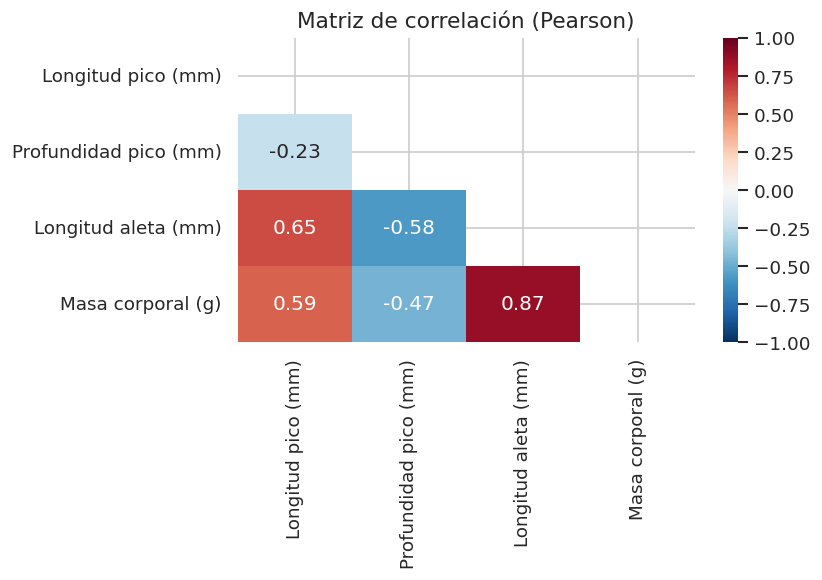

In [12]:
corr = df_clean[numericas].corr()

fig, ax = plt.subplots(figsize=(7, 5))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    mask=mask,
    ax=ax,
    xticklabels=etiquetas,
    yticklabels=etiquetas,
)

ax.set_title("Matriz de correlación (Pearson)", fontsize=13)
plt.tight_layout()
plt.show()

**Hallazgos:**
- La **longitud de aleta** y la **masa corporal** tienen la correlación más alta (0.87): pingüinos más grandes tienen aletas más largas.
- La **profundidad del pico** correlaciona negativamente con la longitud de la aleta y la masa corporal, lo que podría deberse a diferencias morfológicas entre especies.

> **Nota:** Correlación no implica causalidad. El signo negativo en la profundidad del pico puede ser un efecto de la mezcla de especies (*Simpson's Paradox*).

### 4.2 Distribuciones por especie

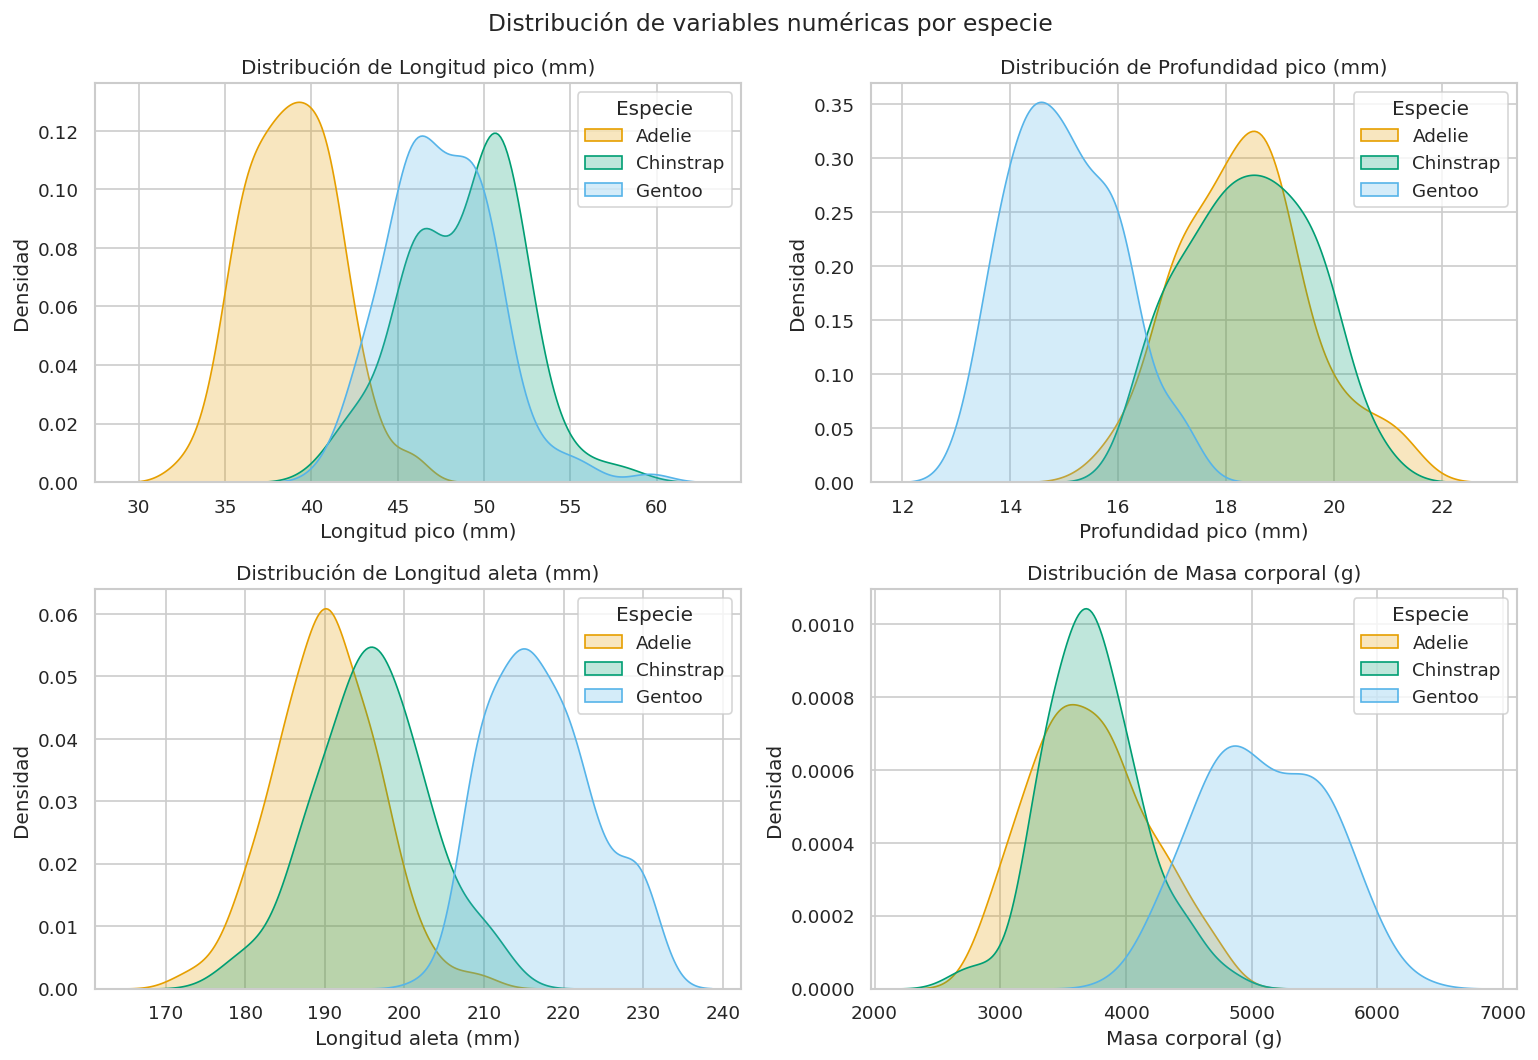

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col, etiqueta in zip(axes.flat, numericas, etiquetas):
    for especie, color in COLORES_ESPECIE.items():
        datos = df_clean.loc[df_clean["species"] == especie, col]
        sns.kdeplot(datos, ax=ax, label=especie, color=color, fill=True, alpha=0.25)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Densidad")
    ax.set_title(f"Distribución de {etiqueta}")
    ax.legend(title="Especie")

fig.suptitle("Distribución de variables numéricas por especie", fontsize=14)
plt.tight_layout()
plt.show()

**Hallazgos:**
- **Gentoo** tiene las aletas más largas y mayor masa corporal, claramente separada de las otras dos especies.
- **Adelie** y **Chinstrap** son similares en longitud de aleta y masa, pero difieren en la **longitud del pico** (Chinstrap la tiene mayor).
- La **profundidad del pico** es lo que más distingue a Adelie de Chinstrap.

### 4.3 Boxplots por especie

/tmp/ipykernel_8952/3530709420.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='species', y=col, ax=ax,
/tmp/ipykernel_8952/3530709420.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df_clean, x='species', y=col, ax=ax,
/tmp/ipykernel_8952/3530709420.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='species', y=col, ax=ax,
/tmp/ipykernel_8952/3530709420.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `

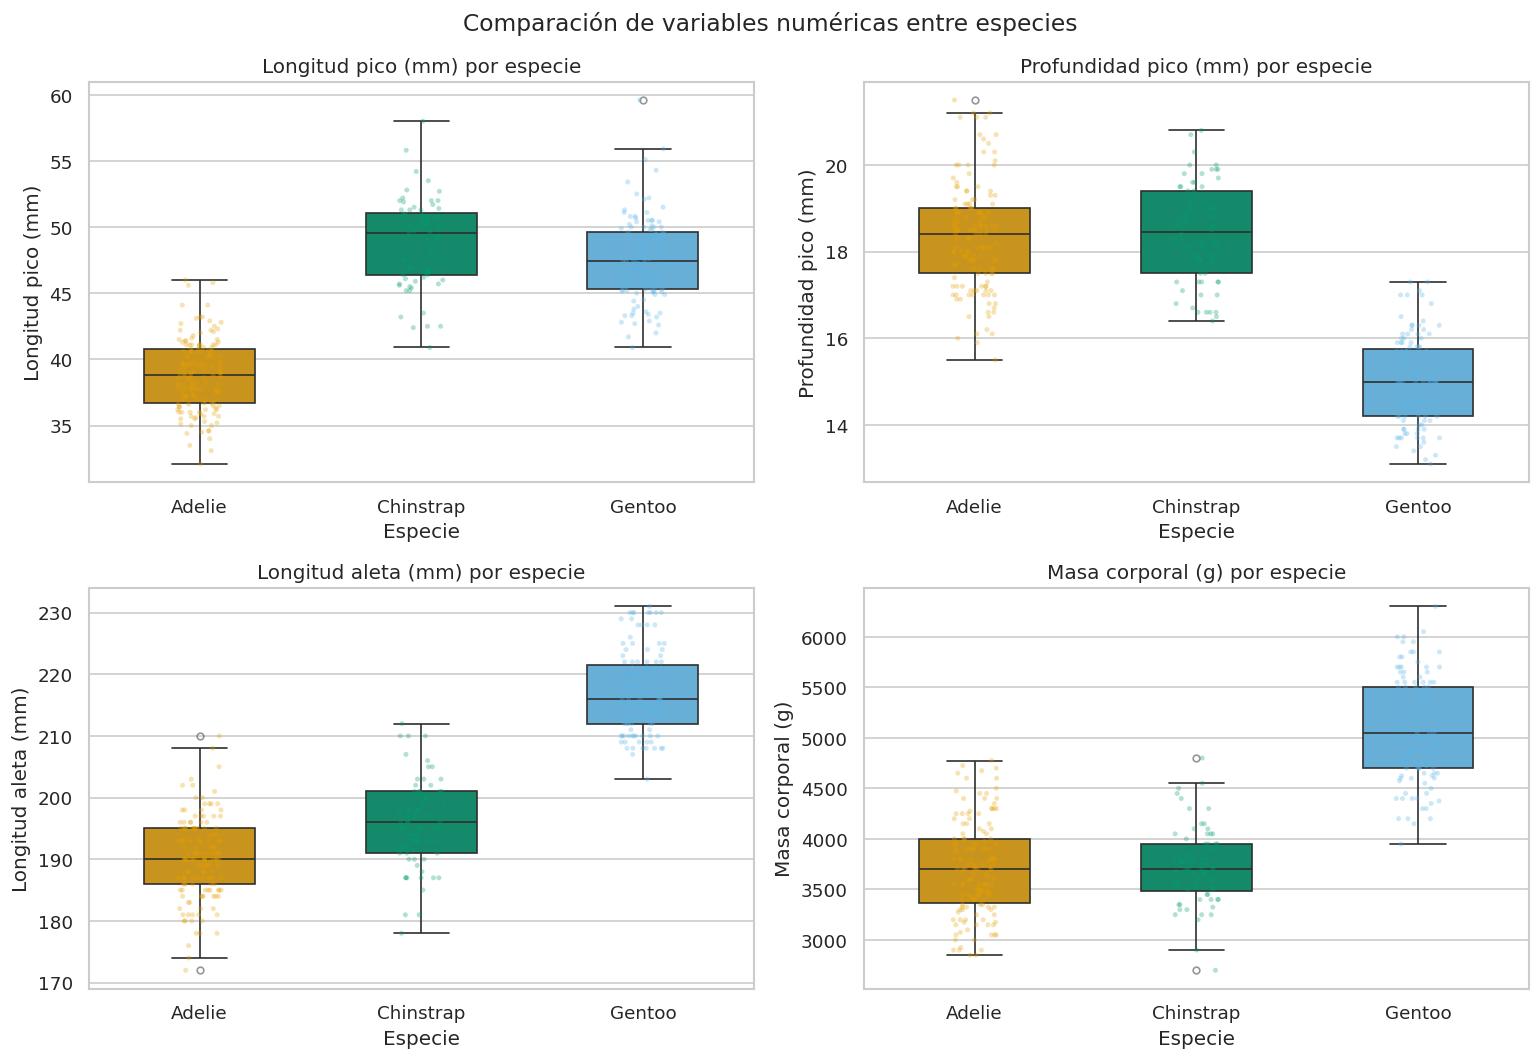

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col, etiqueta in zip(axes.flat, numericas, etiquetas):
    sns.boxplot(
        data=df_clean,
        x="species",
        y=col,
        ax=ax,
        palette=COLORES_ESPECIE,
        width=0.5,
        flierprops={"marker": "o", "markersize": 4, "alpha": 0.5},
    )
    sns.stripplot(
        data=df_clean,
        x="species",
        y=col,
        ax=ax,
        palette=COLORES_ESPECIE,
        size=3,
        alpha=0.3,
        jitter=True,
    )
    ax.set_xlabel("Especie")
    ax.set_ylabel(etiqueta)
    ax.set_title(f"{etiqueta} por especie")

fig.suptitle("Comparación de variables numéricas entre especies", fontsize=14)
plt.tight_layout()
plt.show()

### 4.4 Relación entre pico y especie

Las dimensiones del pico son clave en taxonomía de aves. Analicemos si permiten distinguir especies.

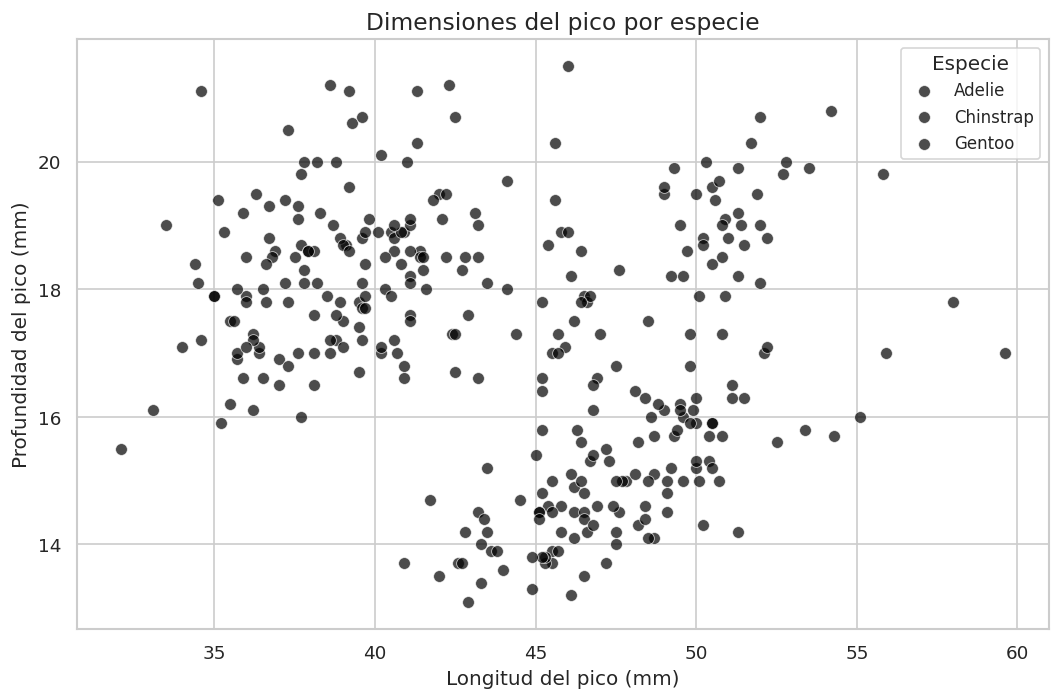

In [15]:
fig, ax = plt.subplots(figsize=(9, 6))

for especie, color in COLORES_ESPECIE.items():
    sub = df_clean[df_clean["species"] == especie]
    ax.scatter(
        sub["bill_length_mm"],
        sub["bill_depth_mm"],
        label=especie,
        color="black",
        alpha=0.7,
        s=50,
        edgecolors="white",
        linewidth=0.5,
    )

ax.set_xlabel("Longitud del pico (mm)", fontsize=12)
ax.set_ylabel("Profundidad del pico (mm)", fontsize=12)
ax.set_title("Dimensiones del pico por especie", fontsize=14)
ax.legend(title="Especie", fontsize=10)

plt.tight_layout()
plt.show()

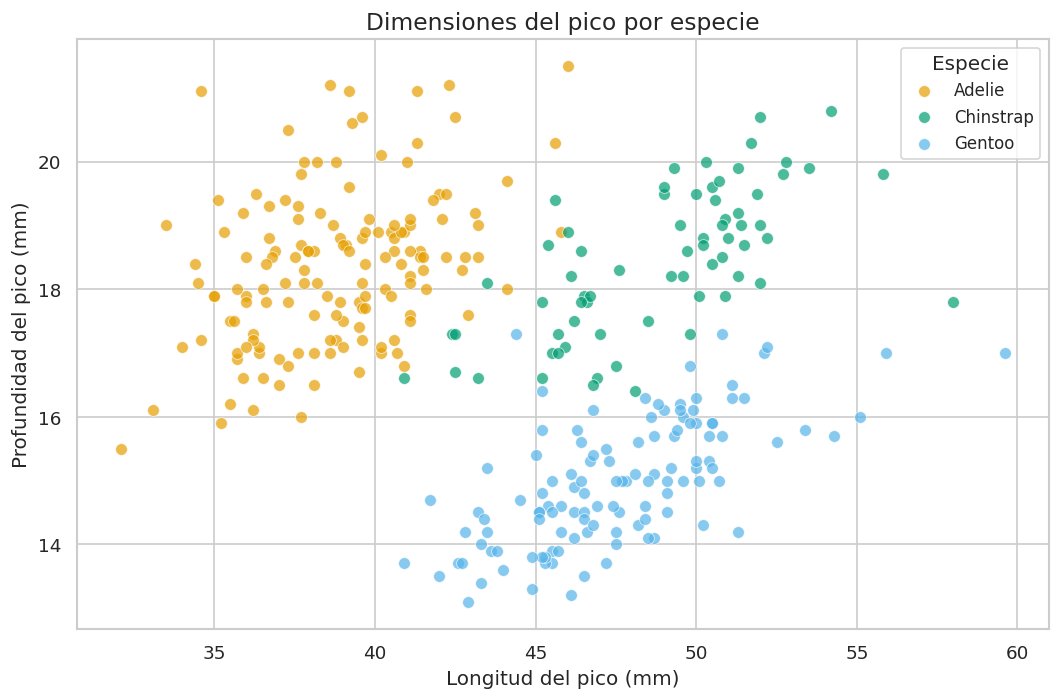

In [16]:
fig, ax = plt.subplots(figsize=(9, 6))

for especie, color in COLORES_ESPECIE.items():
    sub = df_clean[df_clean["species"] == especie]
    ax.scatter(
        sub["bill_length_mm"],
        sub["bill_depth_mm"],
        label=especie,
        color=color,
        alpha=0.7,
        s=50,
        edgecolors="white",
        linewidth=0.5,
    )

ax.set_xlabel("Longitud del pico (mm)", fontsize=12)
ax.set_ylabel("Profundidad del pico (mm)", fontsize=12)
ax.set_title("Dimensiones del pico por especie", fontsize=14)
ax.legend(title="Especie", fontsize=10)

plt.tight_layout()
plt.show()

Este gráfico ilustra el concepto de **Paradoja de Simpson**: usando solo la longitud del pico, la correlación con profundidad parece negativa (mezcla de especies). Al separar por especie, vemos que la correlación es positiva dentro de cada grupo.

### 4.5 Variables categóricas cruzadas

In [ ]:
# Tabla cruzada especie × isla
tabla = pd.crosstab(df_clean["species"], df_clean["island"])
print("Distribución de especies por isla:")
print(tabla)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Heatmap de conteos
sns.heatmap(tabla, annot=True, fmt="d", cmap="Blues", linewidths=0.5, ax=axes[0])
axes[0].set_title("Conteo: Especie × Isla", fontsize=12)
axes[0].set_xlabel("Isla")
axes[0].set_ylabel("Especie")

# Barras agrupadas
tabla.T.plot(
    kind="bar",
    ax=axes[1],
    color=list(COLORES_ESPECIE.values()),
    edgecolor="white",
    rot=0,
)
axes[1].set_title("Distribución por isla y especie", fontsize=12)
axes[1].set_xlabel("Isla")
axes[1].set_ylabel("Conteo")
axes[1].legend(title="Especie")

plt.tight_layout()
plt.show()

**Hallazgo importante:**
- **Gentoo** habita exclusivamente en Biscoe.
- **Chinstrap** habita exclusivamente en Dream.
- **Adelie** es la única especie presente en las tres islas.

Esto significa que la isla es un predictor casi perfecto para Gentoo y Chinstrap.

## 5. Análisis multivariado

### 5.1 Pair plot: todas las variables numéricas por especie

In [ ]:
g = sns.pairplot(
    df_clean,
    vars=numericas,
    hue="species",
    palette=COLORES_ESPECIE,
    diag_kind="kde",
    plot_kws={"alpha": 0.6, "s": 30},
    diag_kws={"fill": True, "alpha": 0.4},
)

# Renombrar ejes
etiquetas_cortas = ["Long. pico", "Prof. pico", "Long. aleta", "Masa"]
for ax, etq in zip(g.axes[-1], etiquetas_cortas):
    ax.set_xlabel(etq)
for ax, etq in zip(g.axes[:, 0], etiquetas_cortas):
    ax.set_ylabel(etq)

g.figure.suptitle("Pair plot: variables numéricas por especie", y=1.01, fontsize=14)
plt.show()

### 5.2 Efecto del sexo dentro de cada especie

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Masa corporal por especie y sexo
sns.boxplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="sex",
    palette="Set2",
    ax=axes[0],
    flierprops={"marker": "o", "markersize": 4, "alpha": 0.5},
)
axes[0].set_title("Masa corporal por especie y sexo")
axes[0].set_xlabel("Especie")
axes[0].set_ylabel("Masa corporal (g)")
axes[0].legend(title="Sexo")

# Longitud pico por especie y sexo
sns.boxplot(
    data=df_clean,
    x="species",
    y="bill_length_mm",
    hue="sex",
    palette="Set2",
    ax=axes[1],
    flierprops={"marker": "o", "markersize": 4, "alpha": 0.5},
)
axes[1].set_title("Longitud del pico por especie y sexo")
axes[1].set_xlabel("Especie")
axes[1].set_ylabel("Longitud del pico (mm)")
axes[1].legend(title="Sexo")

plt.tight_layout()
plt.show()

### 5.3 Resumen estadístico por especie

In [ ]:
resumen = df_clean.groupby("species")[numericas].agg(["mean", "std"]).round(2)
resumen.columns = ["_".join(col) for col in resumen.columns]
resumen

### 5.4 Radar chart: perfil morfológico promedio por especie

In [ ]:
# Normalizar variables entre 0 y 1 para comparar en la misma escala
df_norm = df_clean.copy()
for col in numericas:
    mn, mx = df_clean[col].min(), df_clean[col].max()
    df_norm[col] = (df_clean[col] - mn) / (mx - mn)

medias = df_norm.groupby("species")[numericas].mean()

# Configuración del radar
categorias_radar = ["Long.\npico", "Prof.\npico", "Long.\naleta", "Masa"]
N = len(categorias_radar)
angulos = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angulos += angulos[:1]  # cerrar el polígono

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"polar": True})

for especie, color in COLORES_ESPECIE.items():
    valores = medias.loc[especie].tolist()
    valores += valores[:1]
    ax.plot(angulos, valores, "o-", linewidth=2, label=especie, color=color)
    ax.fill(angulos, valores, alpha=0.15, color=color)

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(categorias_radar, fontsize=11)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=7)
ax.set_title(
    "Perfil morfológico promedio por especie\n(valores normalizados)",
    fontsize=13,
    pad=20,
)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), title="Especie")

plt.tight_layout()
plt.show()

## 6. Conclusiones

El análisis exploratorio nos reveló los siguientes hallazgos clave:

### Estructura del dataset
- 344 registros, 11 con valores faltantes (< 3.5%).
- Tres especies con distribución desbalanceada: Adelie (≈44%), Gentoo (≈36%), Chinstrap (≈20%).

### Diferencias morfológicas entre especies

| Variable | Gentoo | Chinstrap | Adelie |
|---|---|---|---|
| Longitud pico | Media | Alta | Baja |
| Profundidad pico | Baja | Media | Alta |
| Longitud aleta | **Alta** | Media | Baja |
| Masa corporal | **Alta** | Media | Baja |

### Variables más discriminantes
1. **Longitud de aleta** y **masa corporal**: separan claramente a Gentoo del resto.
2. **Longitud del pico**: distingue Chinstrap de Adelie.
3. **Isla**: predictor casi perfecto para Gentoo (Biscoe) y Chinstrap (Dream).

### Implicaciones para modelos predictivos
- El dataset es **altamente separable**: un clasificador simple podría alcanzar alta precisión.
- La **paradoja de Simpson** en la correlación pico-longitud/profundidad muestra la importancia de segmentar por grupos antes de interpretar correlaciones.
- El **dimorfismo sexual** es consistente: los machos son más grandes en todas las especies.

---

> **Siguiente paso**: Con este conocimiento del dataset, podemos construir modelos de clasificación (árboles de decisión, regresión logística) o aplicar clustering para verificar si los grupos emergen sin usar las etiquetas de especie.

In [4]:
# Regresión logística para clasificar pingüinos
# Usaremos tres predictores: longitud de la aleta, masa corporal y sexo.
# La variable objetivo será la especie del pingüino.
# Este modelo responde: ¿cuál especie es más probable dado estas medidas?

import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Cargamos el dataset y eliminamos filas con datos faltantes en las columnas relevantes
penguins = (
    sns.load_dataset("penguins")
    .dropna(subset=["species", "flipper_length_mm", "body_mass_g", "sex"])
    .copy()
)

# Convertimos sexo a una codificación binaria para la regresión logística
penguins["sex"] = penguins["sex"].str.lower().map({"female": 0, "male": 1})

X = penguins[["flipper_length_mm", "body_mass_g", "sex"]]
y = penguins["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
print("\nMatriz de confusión:")
print(confusion_matrix(y_test, predictions, labels=model.classes_))
print("\nReporte de clasificación:")
print(classification_report(y_test, predictions, digits=3))

# Probabilidades por clase para cada observación del conjunto de prueba
probabilidades = model.predict_proba(X_test)
prob_df = pd.DataFrame(
    probabilidades,
    columns=model.classes_,
    index=X_test.index,
)
prob_df["prediccion"] = predictions
prob_df["real"] = y_test.values

print("\nProbabilidades por clase (primeras 5 filas):")
print(prob_df.head().round(4))

print("\nCoeficientes del modelo:")
for clase, intercept, flipper, mass, sex in zip(
    model.classes_,
    model.intercept_,
    model.coef_[:, 0],
    model.coef_[:, 1],
    model.coef_[:, 2],
):
    print(
        f"{clase:10s} | intercept={intercept:>7.3f} | "
        f"flipper={flipper:>7.3f} | mass={mass:>7.3f} | sex={sex:>7.3f}"
    )

Accuracy: 0.833

Matriz de confusión:
[[35  2  0]
 [12  5  0]
 [ 0  0 30]]

Reporte de clasificación:
              precision    recall  f1-score   support

      Adelie      0.745     0.946     0.833        37
   Chinstrap      0.714     0.294     0.417        17
      Gentoo      1.000     1.000     1.000        30

    accuracy                          0.833        84
   macro avg      0.820     0.747     0.750        84
weighted avg      0.830     0.833     0.809        84


Probabilidades por clase (primeras 5 filas):
     Adelie  Chinstrap  Gentoo prediccion       real
190  0.4571     0.5429  0.0000  Chinstrap  Chinstrap
289  0.0000     0.0001  0.9999     Gentoo     Gentoo
112  0.5677     0.4323  0.0001     Adelie     Adelie
236  0.0377     0.1242  0.8381     Gentoo     Gentoo
203  0.4398     0.5580  0.0022  Chinstrap  Chinstrap

Coeficientes del modelo:
Adelie     | intercept= 50.957 | flipper= -0.241 | mass= -0.000 | sex=  0.862
Chinstrap  | intercept= 24.995 | flipper= -0.088 

=== Proporciones por variable categórica ===

Variable: species
            train    test
species                  
Adelie     0.4378  0.4405
Chinstrap  0.2048  0.2024
Gentoo     0.3574  0.3571
Diferencia máxima absoluta entre proporciones: 0.0027

Variable: sex_label
            train    test
sex_label                
female     0.4779  0.5476
male       0.5221  0.4524
Diferencia máxima absoluta entre proporciones: 0.0697

Variable: island
            train    test
island                   
Biscoe     0.4819  0.5119
Dream      0.3655  0.3810
Torgersen  0.1526  0.1071
Diferencia máxima absoluta entre proporciones: 0.0455

=== Resumen estadístico de variables numéricas ===
                   train                                                           test                                                            
                   count     mean     std     min     25%     50%     75%     max count     mean     std     min      25%      50%      75%     max
flipper_length_mm  249.

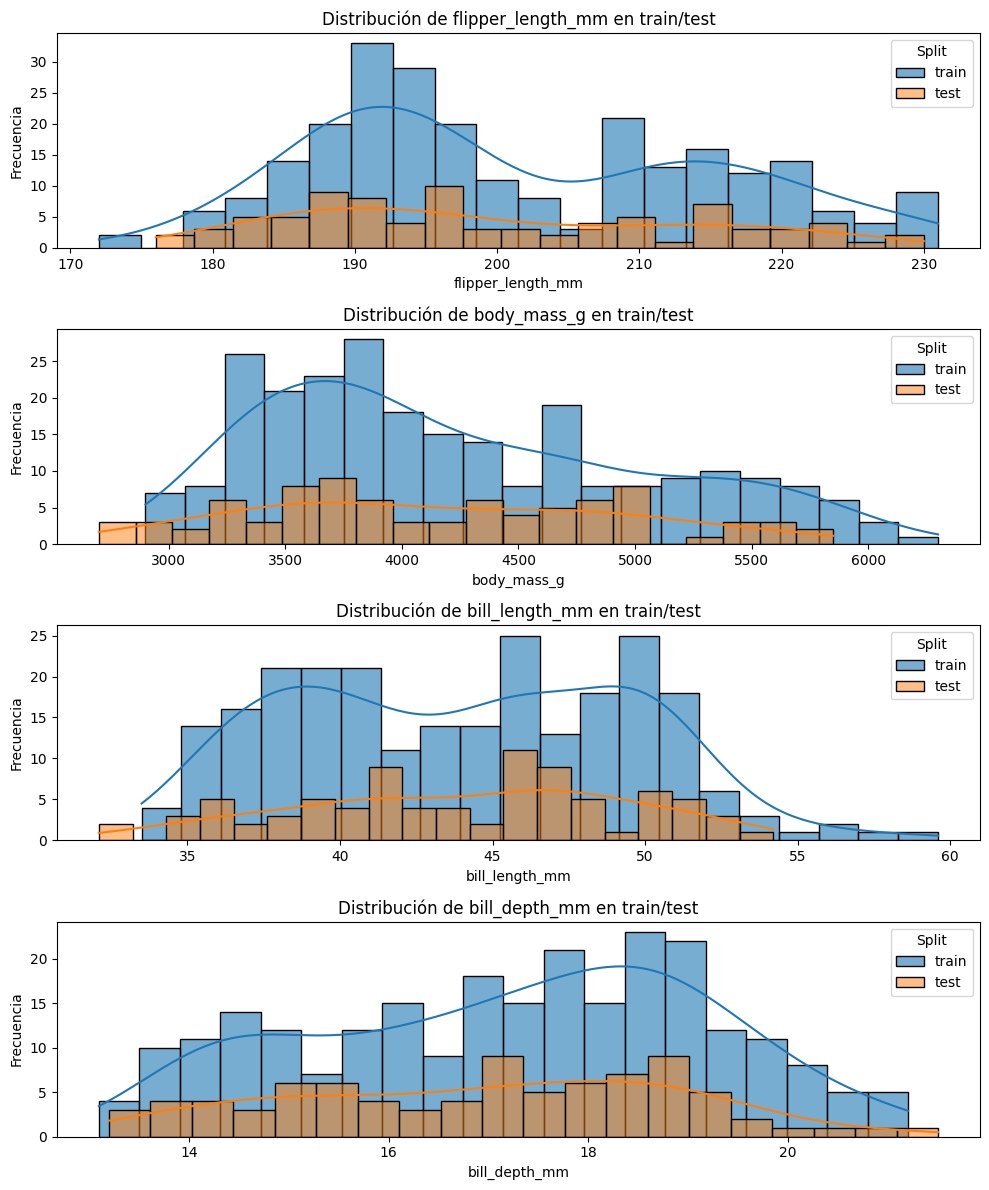

In [6]:
# Comparación de train vs test
# 1) Proporciones de variables categóricas
# 2) Resumen estadístico de variables numéricas
# 3) Distribuciones gráficas de variables numéricas

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Construimos los dataframes de train y test usando el dataframe original
train_df = penguins.loc[X_train.index].copy()
test_df = penguins.loc[X_test.index].copy()
train_df["split"] = "train"
test_df["split"] = "test"

# Mapeamos el sexo codificado de vuelta a texto para la comparación
train_df["sex_label"] = train_df["sex"].map({0: "female", 1: "male"})
test_df["sex_label"] = test_df["sex"].map({0: "female", 1: "male"})

print("=== Proporciones por variable categórica ===")
for col in ["species", "sex_label", "island"]:
    train_prop = train_df[col].value_counts(normalize=True).sort_index()
    test_prop = test_df[col].value_counts(normalize=True).sort_index()
    prop_df = pd.concat({"train": train_prop, "test": test_prop}, axis=1).fillna(0)
    prop_df.columns = ["train", "test"]
    print(f"\nVariable: {col}")
    print(prop_df.round(4).to_string())
    print(
        "Diferencia máxima absoluta entre proporciones:",
        round((prop_df["train"] - prop_df["test"]).abs().max(), 4),
    )

print("\n=== Resumen estadístico de variables numéricas ===")
num_cols = ["flipper_length_mm", "body_mass_g", "bill_length_mm", "bill_depth_mm"]
summary = pd.concat(
    {
        "train": train_df[num_cols].describe().T,
        "test": test_df[num_cols].describe().T,
    },
    axis=1,
)
print(summary.round(2).to_string())

print("\n=== Distribuciones numéricas por split ===")
plot_df = pd.concat(
    [train_df[num_cols].assign(split="train"), test_df[num_cols].assign(split="test")],
    ignore_index=True,
)
plot_df["split"] = pd.Categorical(plot_df["split"], categories=["train", "test"])

fig, axes = plt.subplots(len(num_cols), 1, figsize=(10, 12), sharex=False)
for ax, col in zip(axes, num_cols):
    sns.histplot(
        data=train_df,
        x=col,
        ax=ax,
        bins=20,
        color="#1f77b4",
        alpha=0.6,
        label="train",
        kde=True,
    )
    sns.histplot(
        data=test_df,
        x=col,
        ax=ax,
        bins=20,
        color="#ff7f0e",
        alpha=0.5,
        label="test",
        kde=True,
    )
    ax.set_title(f"Distribución de {col} en train/test")
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
    ax.legend(title="Split")

plt.tight_layout()
plt.show()